# Taller — Lógica difusa: sistemas de inferencia y clasificación con reglas
**Inteligencia Computacional Aplicada · Maestría en Ciencias de la Información y las Comunicaciones · UDFJC**


## Paso 0. Preparar el entorno
Importamos librerías, fijamos la semilla y definimos `verificar`, que imprime `[OK]` o `[REVISAR]`.

In [5]:
# ---- Preparación del entorno ----
import random, time, itertools
import numpy as np
import matplotlib.pyplot as plt

try:
    import skfuzzy as fuzz                       # scikit-fuzzy: se usa para COMPARAR con nuestro código
    from skfuzzy import control as ctrl
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-fuzzy"], check=False)
    import skfuzzy as fuzz
    from skfuzzy import control as ctrl

SEMILLA = 42
def fijar_semilla(s=SEMILLA):
    random.seed(s); np.random.seed(s)
fijar_semilla()
print("NumPy", np.__version__, "| scikit-fuzzy", fuzz.__version__)

def verificar(nombre, ok, pista=""):
    """Punto de control: imprime [OK] o [REVISAR] con una pista."""
    print(("[OK]      " if ok else "[REVISAR] ") + nombre + ("" if ok else "  ->  " + pista))
    return ok


NumPy 2.1.3 | scikit-fuzzy 0.5.0


## Paso 1. Conjuntos difusos y funciones de pertenencia
Un conjunto clásico dice «sí» o «no». Un conjunto difuso asigna a cada elemento un **grado** $\mu(x)\in[0,1]$. Usamos los mismos parámetros que MATLAB:

- `trimf(x,[a b c])`: triángulo con pico en $b$.
- `trapmf(x,[a b c d])`: trapecio con meseta entre $b$ y $c$.
- `gaussmf(x,[σ c])`: campana de ancho $\sigma$ centrada en $c$.

**Importante:** el grado de pertenencia **no es una probabilidad**. «La temperatura es alta con grado 0.7» describe *cuánto* cumple una propiedad vaga, no la probabilidad de que ocurra.

In [6]:
# ---- Funciones de pertenencia (mismos parámetros que en MATLAB) ----
def trimf(x, a, b, c):
    """Triangular [a b c]."""
    x = np.asarray(x, dtype=float)
    izq = np.ones_like(x) if b == a else (x - a) / (b - a)
    der = np.ones_like(x) if c == b else (c - x) / (c - b)
    return np.clip(np.minimum(izq, der), 0.0, 1.0)

def trapmf(x, a, b, c, d):
    """Trapezoidal [a b c d]."""
    x = np.asarray(x, dtype=float)
    izq = np.ones_like(x) if b == a else (x - a) / (b - a)
    der = np.ones_like(x) if d == c else (d - x) / (d - c)
    return np.clip(np.minimum(np.minimum(izq, 1.0), der), 0.0, 1.0)

def gaussmf(x, sigma, c):
    """Gaussiana [sigma c] (el orden de MATLAB: primero sigma, luego el centro)."""
    x = np.asarray(x, dtype=float)
    return np.exp(-((x - c) ** 2) / (2.0 * sigma ** 2))

_MF = {"trimf": trimf, "trapmf": trapmf, "gaussmf": gaussmf}
def mf(tipo, params, x):
    return _MF[tipo](x, *params)


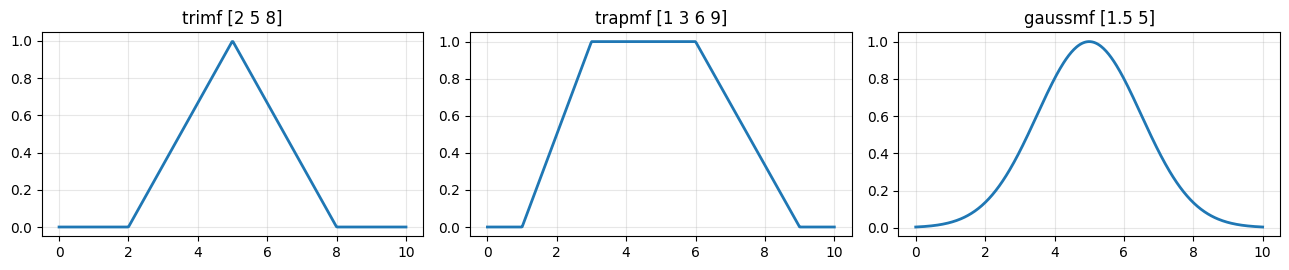

In [7]:
x = np.linspace(0, 10, 400)
fig, ax = plt.subplots(1, 3, figsize=(13, 2.8))
for a, (n, y) in zip(ax, [("trimf [2 5 8]", trimf(x, 2, 5, 8)), ("trapmf [1 3 6 9]", trapmf(x, 1, 3, 6, 9)), ("gaussmf [1.5 5]", gaussmf(x, 1.5, 5))]):
    a.plot(x, y, lw=2); a.set_title(n); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [8]:
# PUNTO DE CONTROL 1
verificar("trimf(5; [2 5 8]) = 1", abs(float(trimf(5, 2, 5, 8)) - 1) < 1e-9, "el pico vale 1")
verificar("gaussmf(3.5; sigma=1.5, c=5) = exp(-0.5) = 0.6065", abs(float(gaussmf(3.5, 1.5, 5)) - 0.6065) < 1e-3, "recuerde el orden [sigma c]")
verificar("trapmf(2; [-2 0 1 3]) = 0.5", abs(float(trapmf(2, -2, 0, 1, 3)) - 0.5) < 1e-9, "baje por el flanco derecho")
# comparación con scikit-fuzzy
xs = np.linspace(0, 10, 101)
verificar("trimf coincide con scikit-fuzzy", np.allclose(trimf(xs, 2, 5, 8), fuzz.trimf(xs, [2, 5, 8])), "")
verificar("gaussmf coincide con scikit-fuzzy", np.allclose(gaussmf(xs, 1.5, 5), fuzz.gaussmf(xs, 5, 1.5)), "scikit-fuzzy usa (x, media, sigma)")

[OK]      trimf(5; [2 5 8]) = 1
[OK]      gaussmf(3.5; sigma=1.5, c=5) = exp(-0.5) = 0.6065
[OK]      trapmf(2; [-2 0 1 3]) = 0.5
[OK]      trimf coincide con scikit-fuzzy
[OK]      gaussmf coincide con scikit-fuzzy


True

## Paso 2. Operadores: Y, O
- **Y** (t-norma): mínimo $\min(a,b)$ o producto $a\cdot b$.
- **O** (s-norma): máximo $\max(a,b)$ o suma probabilística $a+b-ab$ (`probor` en MATLAB).

Con $a=0.8$ y $b=0.5$: mínimo 0.5, producto 0.4, máximo 0.8, probor 0.9.

In [9]:
a, b = 0.8, 0.5
print("Y  min:", min(a, b), "| producto:", a * b)
print("O  max:", max(a, b), "| probor:", a + b - a * b)

Y  min: 0.5 | producto: 0.4
O  max: 0.8 | probor: 0.9


## Paso 3. Sistema Mamdani «propina» (a mano)
**Problema (el mismo del ejemplo de MathWorks):** calcular el porcentaje de propina (0 a 30 %) según el servicio y la comida (0 a 10).

Reglas:
1. SI servicio es pobre **O** comida es rancia ENTONCES propina es baja
2. SI servicio es bueno ENTONCES propina es media
3. SI servicio es excelente **O** comida es deliciosa ENTONCES propina es generosa

Etapas: **fuzzificar** las entradas → calcular la **fuerza** de cada regla → **implicación** (recortar la salida con el mínimo) → **agregación** (máximo) → **defuzzificación** (centroide).

In [10]:
# ---- Motor de inferencia Mamdani (implicación = mínimo, agregación = máximo, centroide) ----
def t_norma(grados, metodo="min"):
    g = np.asarray(grados, dtype=float)
    return g.min() if metodo == "min" else g.prod()

def s_norma(grados, metodo="max"):
    g = list(grados)
    if metodo == "max":
        return max(g)
    r = g[0]                       # "probor": a + b - a*b
    for v in g[1:]:
        r = r + v - r * v
    return r

def evaluar_mamdani(valores, entradas, salida, reglas, n_puntos=101, and_="min", or_="max"):
    """valores: {entrada: número}. entradas: {nombre: {"mfs": {etiqueta: (tipo, params)}}}.
    salida: {"rango": (lo, hi), "mfs": {...}}. reglas: lista de dicts
    {"si": [(entrada, etiqueta), ...], "op": "and"|"or", "entonces": etiqueta, "peso": 1.0}.
    Devuelve (valor_nítido, detalle)."""
    lo, hi = salida["rango"]
    y = np.linspace(lo, hi, n_puntos)
    agregada = np.zeros_like(y)
    fuerzas = []
    for r in reglas:
        grados = [float(mf(*entradas[v]["mfs"][e], valores[v])) for v, e in r["si"]]
        fuerza = (t_norma(grados, and_) if r["op"] == "and" else s_norma(grados, or_)) * r.get("peso", 1.0)
        fuerzas.append(fuerza)
        recorte = np.minimum(fuerza, mf(*salida["mfs"][r["entonces"]], y))     # implicación
        agregada = np.maximum(agregada, recorte)                                # agregación
    if agregada.sum() == 0:
        return float("nan"), {"y": y, "agregada": agregada, "fuerzas": fuerzas}
    centroide = float((y * agregada).sum() / agregada.sum())                    # defuzzificación
    return centroide, {"y": y, "agregada": agregada, "fuerzas": fuerzas}

def evaluar_sugeno0(valores, entradas, reglas, consts, and_="min", or_="max"):
    """Sugeno de orden cero: salida = sum(w_i * z_i) / sum(w_i). consts: {etiqueta: z}."""
    w, z = [], []
    for r in reglas:
        grados = [float(mf(*entradas[v]["mfs"][e], valores[v])) for v, e in r["si"]]
        w.append((t_norma(grados, and_) if r["op"] == "and" else s_norma(grados, or_)) * r.get("peso", 1.0))
        z.append(consts[r["entonces"]])
    w, z = np.array(w), np.array(z)
    return float((w * z).sum() / w.sum()), w

def graficar_mfs(universo, mfs, titulo="", ax=None):
    x = np.linspace(*universo, 400)
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 2.8))
    for etiqueta, (tipo, p) in mfs.items():
        ax.plot(x, mf(tipo, p, x), label=etiqueta, lw=2)
    ax.set_title(titulo); ax.set_ylim(-0.02, 1.05); ax.grid(alpha=.3); ax.legend(fontsize=8)
    return ax


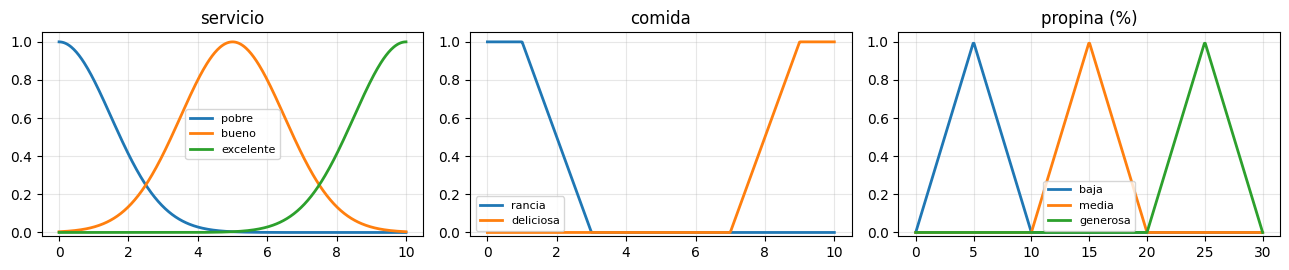

In [11]:
# ---- El sistema «propina» (tipper): mismo que el ejemplo de MathWorks ----
# Entradas: servicio y comida (0 a 10). Salida: propina (0 a 30 %).
entradas = {
    "servicio": {"rango": (0, 10), "mfs": {"pobre": ("gaussmf", (1.5, 0)),
                                          "bueno": ("gaussmf", (1.5, 5)),
                                          "excelente": ("gaussmf", (1.5, 10))}},
    "comida":   {"rango": (0, 10), "mfs": {"rancia": ("trapmf", (-2, 0, 1, 3)),
                                          "deliciosa": ("trapmf", (7, 9, 10, 12))}},
}
salida = {"rango": (0, 30), "mfs": {"baja": ("trimf", (0, 5, 10)),
                                    "media": ("trimf", (10, 15, 20)),
                                    "generosa": ("trimf", (20, 25, 30))}}
reglas = [
    {"si": [("servicio", "pobre"), ("comida", "rancia")], "op": "or", "entonces": "baja"},
    {"si": [("servicio", "bueno")], "op": "and", "entonces": "media"},
    {"si": [("servicio", "excelente"), ("comida", "deliciosa")], "op": "or", "entonces": "generosa"},
]
fig, ejes = plt.subplots(1, 3, figsize=(13, 2.8))
graficar_mfs((0, 10), entradas["servicio"]["mfs"], "servicio", ejes[0])
graficar_mfs((0, 10), entradas["comida"]["mfs"], "comida", ejes[1])
graficar_mfs((0, 30), salida["mfs"], "propina (%)", ejes[2])
plt.tight_layout(); plt.show()


Fuerza de cada regla: [0.8007 0.0286 0.    ]
Propina (centroide): 5.5586 %


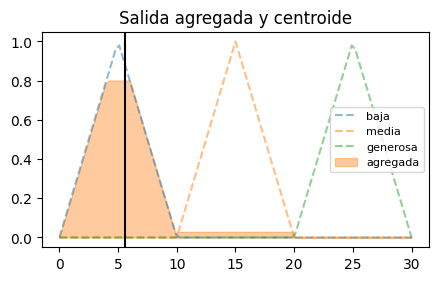

In [12]:
valores = {"servicio": 1, "comida": 2}
propina, det = evaluar_mamdani(valores, entradas, salida, reglas)
print("Fuerza de cada regla:", np.round(det["fuerzas"], 4))
print("Propina (centroide): %.4f %%" % propina)
plt.figure(figsize=(5, 2.8))
for et, (t, p) in salida["mfs"].items():
    plt.plot(det["y"], mf(t, p, det["y"]), "--", alpha=.5, label=et)
plt.fill_between(det["y"], det["agregada"], alpha=.4, color="tab:orange", label="agregada")
plt.axvline(propina, color="k"); plt.legend(fontsize=8); plt.title("Salida agregada y centroide"); plt.show()

In [13]:
# PUNTO DE CONTROL 2: comparar con la referencia de MathWorks y con scikit-fuzzy
# Referencia: en MATLAB, evalfis(fis, [1 2]) devuelve 5.5586 para este mismo sistema.
verificar("Coincide con la referencia de MathWorks (5.5586)", abs(propina - 5.5586) < 0.01, "revise parámetros de las funciones de pertenencia")

sv = ctrl.Antecedent(np.arange(0, 10.01, .1), "s"); cm = ctrl.Antecedent(np.arange(0, 10.01, .1), "c"); pr = ctrl.Consequent(np.arange(0, 30.01, .1), "p")
sv["pobre"] = fuzz.gaussmf(sv.universe, 0, 1.5); sv["bueno"] = fuzz.gaussmf(sv.universe, 5, 1.5); sv["exc"] = fuzz.gaussmf(sv.universe, 10, 1.5)
cm["rancia"] = fuzz.trapmf(cm.universe, [-2, 0, 1, 3]); cm["del"] = fuzz.trapmf(cm.universe, [7, 9, 10, 12])
pr["baja"] = fuzz.trimf(pr.universe, [0, 5, 10]); pr["media"] = fuzz.trimf(pr.universe, [10, 15, 20]); pr["gen"] = fuzz.trimf(pr.universe, [20, 25, 30])
sis = ctrl.ControlSystemSimulation(ctrl.ControlSystem([ctrl.Rule(sv["pobre"] | cm["rancia"], pr["baja"]),
                                                       ctrl.Rule(sv["bueno"], pr["media"]),
                                                       ctrl.Rule(sv["exc"] | cm["del"], pr["gen"])]))
sis.input["s"] = 1; sis.input["c"] = 2; sis.compute()
print("scikit-fuzzy:", round(float(sis.output["p"]), 4), "| nuestro código:", round(propina, 4))
verificar("Nuestro Mamdani ≈ scikit-fuzzy (diferencia < 0.05 por la discretización)", abs(propina - float(sis.output["p"])) < 0.05, "")

[OK]      Coincide con la referencia de MathWorks (5.5586)
scikit-fuzzy: 5.5539 | nuestro código: 5.5586
[OK]      Nuestro Mamdani ≈ scikit-fuzzy (diferencia < 0.05 por la discretización)


True

**Qué observar.** Con servicio 1 (pobre) y comida 2 (algo rancia), solo se activa con fuerza la regla 1; la propina queda cerca del centro de «baja» (5 %). El resultado no es exactamente 5 porque la regla 2 se activa débilmente y desplaza el centroide.

**Superficie de control.** Pruebe valores distintos en `valores` y vea cómo cambia la propina.

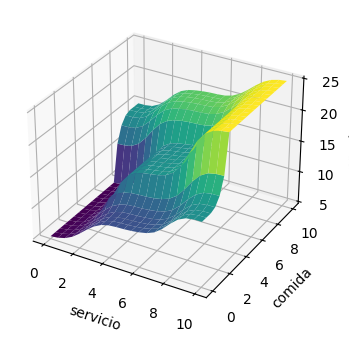

In [14]:
S, K = np.meshgrid(np.linspace(0, 10, 21), np.linspace(0, 10, 21))
Z = np.array([[evaluar_mamdani({"servicio": s, "comida": k}, entradas, salida, reglas)[0] for s, k in zip(fs, fk)] for fs, fk in zip(S, K)])
fig = plt.figure(figsize=(5.5, 4)); ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(S, K, Z, cmap="viridis"); ax.set_xlabel("servicio"); ax.set_ylabel("comida"); ax.set_zlabel("propina %"); plt.show()

## Paso 4. Sugeno de orden cero
En Sugeno la salida de cada regla es una **constante** $z_i$ y la salida final es el promedio ponderado

$$y=\frac{\sum_i w_i z_i}{\sum_i w_i}$$

con $w_i$ la fuerza de la regla $i$. No hay agregación de conjuntos ni centroide: es más rápido y se usa para ajuste automático (en MATLAB, `tunefis`). Constantes: baja = 5, media = 15, generosa = 25.

In [15]:
consts = {"baja": 5, "media": 15, "generosa": 25}
y_sug, w = evaluar_sugeno0(valores, entradas, reglas, consts)
print("Fuerzas w:", np.round(w, 4))
print("Propina Sugeno: %.4f %%   (Mamdani: %.4f %%)" % (y_sug, propina))

Fuerzas w: [0.8007 0.0286 0.    ]
Propina Sugeno: 5.3445 %   (Mamdani: 5.5586 %)


In [16]:
# PUNTO DE CONTROL 3
manual = (w * np.array([5, 15, 25])).sum() / w.sum()
verificar("Sugeno = suma(w*z)/suma(w)", abs(y_sug - manual) < 1e-12, "")
verificar("La salida Sugeno queda entre las constantes 5 y 25", 5 <= y_sug <= 25, "")

[OK]      Sugeno = suma(w*z)/suma(w)
[OK]      La salida Sugeno queda entre las constantes 5 y 25


True

## Paso 5. Clasificador difuso con reglas extraídas de los datos (Iris)
Hasta ahora las reglas las escribió una persona. Aquí las **extraemos de los datos** con una versión simplificada del método de Wang–Mendel:

1. Normalizar cada característica a [0, 1] (con los datos de entrenamiento).
2. Particionar cada característica con $n$ triángulos uniformes (bajo, medio, alto si $n=3$).
3. Cada muestra de entrenamiento genera **una regla**: en cada característica toma la etiqueta con mayor grado; la clase es la de la muestra.
4. Si dos muestras producen el mismo antecedente, se conserva la de mayor grado.
5. Para clasificar, se calcula la fuerza de cada regla con la t-norma producto y gana la regla más fuerte.

In [17]:
# ---- Clasificador difuso con reglas extraídas de los datos (Wang-Mendel simplificado) ----
ETIQ = {2: ["bajo", "alto"], 3: ["bajo", "medio", "alto"],
        4: ["muy bajo", "bajo", "alto", "muy alto"], 5: ["muy bajo", "bajo", "medio", "alto", "muy alto"]}

def normalizar(X, mins, maxs):
    return np.clip((X - mins) / (maxs - mins + 1e-12), 0.0, 1.0)

def grados_pertenencia(Xn, n_mf):
    """Xn en [0,1]. Devuelve G de forma (N, F, n_mf) con n_mf triangulares uniformes."""
    centros = np.linspace(0, 1, n_mf)
    ancho = centros[1] - centros[0]
    G = np.stack([trimf(Xn, c - ancho, c, c + ancho) for c in centros], axis=2)
    return G

def extraer_reglas(Xn, y, n_mf):
    """Una regla por muestra (etiqueta dominante en cada característica); si dos muestras dan el mismo
    antecedente se conserva la de mayor grado. Devuelve (R: n_reglas x F, clases, grados)."""
    G = grados_pertenencia(Xn, n_mf)
    dom = G.argmax(axis=2)                                     # N x F
    grado = np.take_along_axis(G, dom[:, :, None], axis=2)[:, :, 0].prod(axis=1)
    mejores = {}
    for i in range(len(y)):
        clave = tuple(dom[i])
        if clave not in mejores or grado[i] > mejores[clave][1]:
            mejores[clave] = (int(y[i]), float(grado[i]))
    R = np.array(list(mejores.keys()))
    clases = np.array([v[0] for v in mejores.values()])
    grados = np.array([v[1] for v in mejores.values()])
    return R, clases, grados

def predecir_reglas(Xn, R, clases, n_mf, defecto=0):
    G = grados_pertenencia(Xn, n_mf)                           # N x F x n_mf
    F = G.shape[1]
    fuerza = G[:, np.arange(F)[None, :], R].prod(axis=2)        # N x n_reglas (t-norma = producto)
    pred = clases[fuerza.argmax(axis=1)]
    pred = np.where(fuerza.max(axis=1) > 0, pred, defecto)
    return pred, fuerza

def reglas_en_palabras(R, clases, grados, nombres_car, nombres_clase, n_mf, max_reglas=10):
    et = ETIQ[n_mf]
    orden = np.argsort(-grados)[:max_reglas]
    for k in orden:
        cond = " Y ".join(f"{nombres_car[f]} es {et[R[k, f]]}" for f in range(R.shape[1]))
        print(f"SI {cond} ENTONCES clase = {nombres_clase[clases[k]]}   (grado {grados[k]:.2f})")


In [18]:
# ---- Datos: conjuntos clásicos de la UCI incluidos en scikit-learn (no requieren internet) ----
def cargar_crudo(nombre="iris", test=0.3):
    from sklearn.datasets import load_iris, load_wine, load_breast_cancer
    from sklearn.model_selection import train_test_split
    d = {"iris": load_iris, "wine": load_wine, "breast_cancer": load_breast_cancer}[nombre]()
    Xtr, Xte, ytr, yte = train_test_split(d.data, d.target, test_size=test, stratify=d.target, random_state=SEMILLA)
    return dict(nombre=nombre, Xtr=Xtr, Xte=Xte, ytr=ytr, yte=yte,
                car=list(d.feature_names), clases=[str(t) for t in d.target_names])


In [19]:
from sklearn.metrics import accuracy_score, confusion_matrix
d = cargar_crudo("iris")
mins, maxs = d["Xtr"].min(0), d["Xtr"].max(0)          # solo con entrenamiento
Xtr, Xte = normalizar(d["Xtr"], mins, maxs), normalizar(d["Xte"], mins, maxs)
N_MF = 3
R, clases_r, grados_r = extraer_reglas(Xtr, d["ytr"], N_MF)
pred, fuerza = predecir_reglas(Xte, R, clases_r, N_MF)
exactitud = accuracy_score(d["yte"], pred)
print("Muestras de entrenamiento:", len(Xtr), "| reglas obtenidas:", len(R), "| exactitud en prueba: %.3f" % exactitud)
print(confusion_matrix(d["yte"], pred))
reglas_en_palabras(R, clases_r, grados_r, [c.replace(" (cm)", "") for c in d["car"]], d["clases"], N_MF, max_reglas=6)

Muestras de entrenamiento: 105 | reglas obtenidas: 16 | exactitud en prueba: 0.889
[[15  0  0]
 [ 0 15  0]
 [ 0  5 10]]
SI sepal length es bajo Y sepal width es medio Y petal length es bajo Y petal width es bajo ENTONCES clase = setosa   (grado 0.83)
SI sepal length es medio Y sepal width es medio Y petal length es medio Y petal width es medio ENTONCES clase = versicolor   (grado 0.67)
SI sepal length es medio Y sepal width es bajo Y petal length es medio Y petal width es medio ENTONCES clase = versicolor   (grado 0.59)
SI sepal length es medio Y sepal width es medio Y petal length es alto Y petal width es alto ENTONCES clase = virginica   (grado 0.56)
SI sepal length es bajo Y sepal width es bajo Y petal length es bajo Y petal width es bajo ENTONCES clase = setosa   (grado 0.52)
SI sepal length es medio Y sepal width es alto Y petal length es bajo Y petal width es bajo ENTONCES clase = setosa   (grado 0.50)


In [20]:
# PUNTO DE CONTROL 4
verificar("Hay menos reglas que muestras de entrenamiento (reglas repetidas se fusionan)", len(R) < len(Xtr), "")
verificar("Exactitud en prueba > 85 %", exactitud > 0.85, "revise la normalización con mins/maxs de entrenamiento")
verificar("Todas las clases aparecen en las reglas", set(clases_r) == {0, 1, 2}, "")

[OK]      Hay menos reglas que muestras de entrenamiento (reglas repetidas se fusionan)
[OK]      Exactitud en prueba > 85 %
[OK]      Todas las clases aparecen en las reglas


True

**Qué observar.** Cada regla se lee en lenguaje natural: es la ventaja de la lógica difusa frente a una red neuronal. El costo: el número de reglas crece con las muestras y con el número de etiquetas.

## Paso 6. Fuzzy C-Means (agrupamiento difuso)
k-means asigna cada punto a **un** grupo. Fuzzy C-Means (FCM) asigna un **grado** de pertenencia a cada grupo, y los grados de cada punto suman 1. Minimiza

$$J=\sum_{i=1}^{c}\sum_{k=1}^{N}u_{ik}^{m}\,\lVert x_k-v_i\rVert^{2}$$

con exponente de difusidad $m=2$. Se alternan dos pasos: actualizar centros $v_i$ y grados $u_{ik}$. Usamos Iris completo **sin las etiquetas** y comparamos los grupos con las especies mediante el índice de Rand ajustado (ARI; 1 = coincidencia perfecta, ≈ 0 = azar).

In [21]:
# ---- Fuzzy C-Means propio ----
def fcm_propio(X, c=3, m=2.0, iters=300, tol=1e-6, semilla=SEMILLA):
    """X: N x d. Devuelve centros (c x d), U (c x N), historial del objetivo J."""
    rng = np.random.default_rng(semilla)
    U = rng.random((c, len(X))); U /= U.sum(axis=0, keepdims=True)
    J = []
    for _ in range(iters):
        Um = U ** m
        centros = (Um @ X) / Um.sum(axis=1, keepdims=True)
        d = np.linalg.norm(X[None, :, :] - centros[:, None, :], axis=2) + 1e-12      # c x N
        J.append(float((Um * d ** 2).sum()))
        U_nueva = 1.0 / ((d[:, None, :] / d[None, :, :]) ** (2.0 / (m - 1))).sum(axis=1)
        if np.abs(U_nueva - U).max() < tol:
            U = U_nueva; break
        U = U_nueva
    return centros, U, J

def coeficiente_particion(U):
    """FPC = (1/N) * sum de U^2; vale 1/c con partición totalmente borrosa y 1 con partición nítida."""
    return float((U ** 2).sum() / U.shape[1])


Iteraciones: 35 | J final: 5.220
ARI  FCM: 0.729 | k-means: 0.716 | coeficiente de partición: 0.743
Grados del primer punto (suman 1): [0.642 0.127 0.23 ] | de un punto en la frontera: [0.475 0.473 0.052]


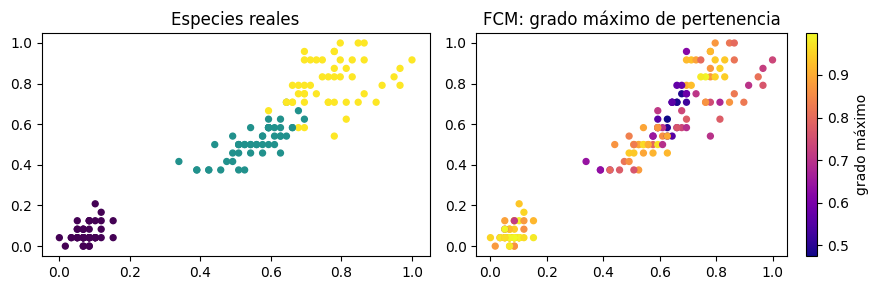

In [22]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
X_all = np.vstack([d["Xtr"], d["Xte"]]); y_all = np.concatenate([d["ytr"], d["yte"]])
Xa = normalizar(X_all, X_all.min(0), X_all.max(0))
centros, U, J = fcm_propio(Xa, c=3, m=2.0)
ari_fcm = adjusted_rand_score(y_all, U.argmax(axis=0))
ari_km = adjusted_rand_score(y_all, KMeans(3, n_init=10, random_state=SEMILLA).fit_predict(Xa))
fpc = coeficiente_particion(U)
print("Iteraciones:", len(J), "| J final: %.3f" % J[-1])
print("ARI  FCM: %.3f | k-means: %.3f | coeficiente de partición: %.3f" % (ari_fcm, ari_km, fpc))
print("Grados del primer punto (suman 1):", np.round(U[:, 0], 3), "| de un punto en la frontera:", np.round(U[:, np.argsort(U.max(axis=0))[0]], 3))
plt.figure(figsize=(9, 3))
plt.subplot(1, 2, 1); plt.scatter(Xa[:, 2], Xa[:, 3], c=y_all, cmap="viridis", s=18); plt.title("Especies reales")
plt.subplot(1, 2, 2); plt.scatter(Xa[:, 2], Xa[:, 3], c=U.max(axis=0), cmap="plasma", s=18); plt.colorbar(label="grado máximo"); plt.title("FCM: grado máximo de pertenencia")
plt.tight_layout(); plt.show()

In [23]:
# PUNTO DE CONTROL 5
verificar("Los grados de cada punto suman 1", np.allclose(U.sum(axis=0), 1), "")
verificar("El objetivo J no aumenta", all(b <= a + 1e-9 for a, b in zip(J, J[1:])), "")
verificar("ARI de FCM > 0.5 (los grupos se parecen a las especies)", ari_fcm > 0.5, "")
cs, Us, *_ = fuzz.cluster.cmeans(Xa.T, 3, 2, error=1e-6, maxiter=300, seed=SEMILLA)
verificar("Nuestro FCM coincide con skfuzzy.cluster.cmeans (ARI entre ambos > 0.9)", adjusted_rand_score(U.argmax(axis=0), Us.argmax(axis=0)) > 0.9, "")

[OK]      Los grados de cada punto suman 1
[OK]      El objetivo J no aumenta
[OK]      ARI de FCM > 0.5 (los grupos se parecen a las especies)
[OK]      Nuestro FCM coincide con skfuzzy.cluster.cmeans (ARI entre ambos > 0.9)


True

## Paso 7. Experimento: reglas, exactitud e interpretabilidad
Variamos el número de etiquetas por característica $n$ y comparamos con un **árbol de decisión que tiene el mismo número de hojas** que reglas obtuvimos (también interpretable).

**Antes de ejecutar, prediga:** ¿la exactitud sube siempre al aumentar $n$? ¿Y el número de reglas?

In [24]:
from sklearn.tree import DecisionTreeClassifier
filas = []
for n in (2, 3, 4, 5):
    Rn, cn, gn = extraer_reglas(Xtr, d["ytr"], n)
    pn, _ = predecir_reglas(Xte, Rn, cn, n)
    arbol = DecisionTreeClassifier(max_leaf_nodes=max(2, len(Rn)), random_state=SEMILLA).fit(d["Xtr"], d["ytr"])
    filas.append((n, len(Rn), accuracy_score(d["yte"], pn), accuracy_score(d["yte"], arbol.predict(d["Xte"]))))
print(f"{'n_mf':>5} {'reglas':>7} {'exact. difusa':>14} {'exact. árbol':>13}")
for n, nr, a1, a2 in filas:
    print(f"{n:>5} {nr:>7} {a1:>14.3f} {a2:>13.3f}")
print("\nCrecimiento máximo teórico con rejilla completa (4 características):", [n ** 4 for n in (2, 3, 4, 5)])

 n_mf  reglas  exact. difusa  exact. árbol
    2       8          0.733         0.933
    3      16          0.889         0.933
    4      26          0.778         0.933
    5      38          0.933         0.933

Crecimiento máximo teórico con rejilla completa (4 características): [16, 81, 256, 625]


In [25]:
# PUNTO DE CONTROL 6
reglas_n = [f[1] for f in filas]
verificar("El número de reglas crece al aumentar n_mf", all(b >= a for a, b in zip(reglas_n, reglas_n[1:])), "")
verificar("Ninguna cantidad de reglas supera n_mf^4", all(f[1] <= f[0] ** 4 for f in filas), "")
print("Conclusión para redactar: ¿qué n_mf elegiría y por qué? (mire exactitud y número de reglas a la vez)")

[OK]      El número de reglas crece al aumentar n_mf
[OK]      Ninguna cantidad de reglas supera n_mf^4
Conclusión para redactar: ¿qué n_mf elegiría y por qué? (mire exactitud y número de reglas a la vez)


**Qué observar.** Más etiquetas permiten fronteras más finas pero producen muchas más reglas (con pocas muestras, casi una regla por muestra) y la exactitud en prueba no mejora de forma sostenida: es la tensión **precisión vs interpretabilidad**. Con una rejilla completa el número de reglas es $n^{F}$ (*explosión de reglas*); por eso en MATLAB `genfis` con `GridPartition` se vuelve impracticable con muchas características y se usa `SubtractiveClustering` o `FCMClustering`.

> **Muestra pequeña:** con 45 datos de prueba, un acierto más o menos cambia la exactitud en 2.2 puntos porcentuales. No saque conclusiones fuertes de diferencias pequeñas.